# Llama-3.2-3B-Instruct: zero-shot (large and small) vs the same small model + LoRA

In [ ]:
!pip install -q -U transformers peft accelerate bitsandbytes datasets spacy sentence-transformers evaluate sacrebleu sacremoses bert-score
!python -m spacy download en_core_web_md -q

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import os, re, json, random, math, time, gc, itertools
from pathlib import Path
from collections import Counter, defaultdict

from google.colab import drive, userdata
drive.mount("/content/drive")

WORKDIR = Path("/content/drive/MyDrive/federalist_lora")
V3_DIR = WORKDIR / "v3"
BASE_DIR = WORKDIR / "baselines"
OUT_DIR = WORKDIR / "ft_llama32_3b"
OUT_DIR.mkdir(parents=True, exist_ok=True)
assert OUT_DIR.resolve() not in (V3_DIR.resolve(), BASE_DIR.resolve())
EVAL_MODELS_DIR = V3_DIR / "eval_models"
clf_dir, alm_dir = EVAL_MODELS_DIR / "style_clf", EVAL_MODELS_DIR / "archaic_lm"
AUDIT_PATH = V3_DIR / "pairs_v3_audit.jsonl"

BASE_MODEL = "meta-llama/Llama-3.2-3B-Instruct"
FOCAL = "Llama-3.2-3B fine-tuned"
OWN_ZS = "Llama-3.2-3B zero-shot"
OWN_LARGE = "Llama-3.1-8B zero-shot"
MODEL_TITLE = "Llama-3.2-3B"

LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.1
EPOCHS, LR, WEIGHT_DECAY = 2, 1e-4, 0.01
MAX_LEN = 1024
BATCH, GRAD_ACCUM = 2, 8
EVALS_PER_EPOCH, EARLY_STOP_PATIENCE = 4, 3
SEED = 42
random.seed(SEED)
EVAL_TEMPERATURE = 0.3
BATCH_GEN = 8

CLF_MAX_LEN = 384
ARCHAIC_LM_BASE = MODERN_LM = "gpt2"
EVAL_EMBEDDER = "sentence-transformers/all-mpnet-base-v2"
BERTSCORE_MODEL = "roberta-large"
N_BOOT = 2000

try:
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
except Exception:
    print("No HF_TOKEN secret found: open models will work, gated ones (Llama) will not.")

Mounted at /content/drive


In [ ]:
import evaluate
_sari = evaluate.load("sari"); print("SARI loads.")

needed = [AUDIT_PATH, clf_dir / "config.json", alm_dir / "config.json", V3_DIR / "outputs_v3_adapter.json",
          BASE_DIR / "outputs_Llama_3_2_3B_zero_shot.json", BASE_DIR / "outputs_Llama_3_1_8B_zero_shot.json"]
missing = [p for p in needed if not p.exists()]
assert not missing, f"missing files: {missing}"
print("required v3 / baselines files found.")

from huggingface_hub import hf_hub_download
try:
    hf_hub_download(BASE_MODEL, "config.json"); print("model access ok:", BASE_MODEL)
except Exception as e:
    raise SystemExit(f"Cannot access {BASE_MODEL} ({type(e).__name__}). Accept its license at https://huggingface.co/{BASE_MODEL} "
                     "with the account that owns your HF_TOKEN secret, enable notebook access for the secret, then rerun.")

SARI loads.
required v3 / baselines files found.


config.json:   0%|          | 0.00/878 [00:00<?, ?B/s]

model access ok: meta-llama/Llama-3.2-3B-Instruct


## 1. Load the training pairs from the v3 audit file
Every pair that the Qwen run used (and every pair it rejected) is recorded in `pairs_v3_audit.jsonl` with its split, kind, similarity, status and paraphrase. Using it guarantees this notebook trains on exactly the same data without regenerating any paraphrases. Pairs with status `ok` are the ones v3 trained, validated and tested on.

In [ ]:
audit_rows = [json.loads(l) for l in AUDIT_PATH.read_text(encoding="utf-8").splitlines()]
print("audit rows:", len(audit_rows))
print("by split / kind / status:", dict(Counter((r["split"], r["kind"], r["status"]) for r in audit_rows)))

V3_IDS = json.loads((V3_DIR / "outputs_v3_adapter.json").read_text(encoding="utf-8"))["ids"]      # the test chunks and order v3 evaluated
test_ok = [r["id"] for r in audit_rows if r["split"] == "test" and r["status"] == "ok"]
assert test_ok == V3_IDS, "test chunks in the audit file differ from the ones v3 evaluated"
print(f"test chunks match v3 exactly ({len(V3_IDS)}).")

audit rows: 2224
by split / kind / status: {('train', 'long', 'ok'): 595, ('train', 'long', 'low_similarity'): 55, ('val', 'long', 'ok'): 65, ('train', 'long', 'length_ratio'): 2, ('test', 'long', 'ok'): 69, ('train', 'short', 'ok'): 1329, ('train', 'short', 'low_similarity'): 106, ('train', 'short', 'no_translation'): 1, ('train', 'short', 'length_ratio'): 2}
test chunks match v3 exactly (69).


## 2. Entity masking (same code as v3)
Placeholders (`[PERSON_1]`, `[GPE_2]`, ...) are created from the Federalist input and reused in the paraphrase; at generation time the same masking is applied to the input and `unmask` restores the names. Test chunks are not masked here: they are masked at generation time.

In [ ]:
import spacy
nlp = spacy.load("en_core_web_md", disable=["lemmatizer", "parser"])
KEEP = {"PERSON", "ORG", "GPE", "LOC", "NORP", "FAC", "EVENT"}

def norm_key(t):
    t = t.lower().strip()
    t = re.sub(r"^(the|a|an)\s+", "", t)
    return re.sub(r"['’]s$", "", t)

def mask_text(text, mapping, counts, surface, create):
    doc = nlp(text); out, last = [], 0
    for ent in doc.ents:
        if ent.label_ not in KEEP: continue
        key = norm_key(ent.text)
        if key in mapping:
            repl = mapping[key]
        elif create:
            counts[ent.label_] += 1
            repl = f"[{ent.label_}_{counts[ent.label_]}]"
            mapping[key] = repl; surface[repl] = ent.text
        else:
            continue
        out += [text[last:ent.start_char], repl]; last = ent.end_char
    out.append(text[last:])
    return "".join(out)

def mask_pair(original, modern):
    mapping, counts, surface = {}, defaultdict(int), {}
    o = mask_text(original, mapping, counts, surface, create=True)
    m = mask_text(modern, mapping, counts, surface, create=False)
    return o, m

def mask_input(text):
    mapping, counts, surface = {}, defaultdict(int), {}
    return mask_text(text, mapping, counts, surface, True), surface

def unmask(text, surface):
    for ph, s in surface.items():
        text = text.replace(ph, s)
    return text

pairs = []
for r in audit_rows:
    if r["status"] != "ok": continue
    p = dict(r)
    if p["split"] != "test":
        p["original_masked"], p["modern_masked"] = mask_pair(p["original"], p["modern"])
    pairs.append(p)

trainval = [p for p in pairs if "original_masked" in p]
stray = Counter(t for p in trainval for t in re.findall(r"\[[A-Z]+\]", p["modern_masked"] + " " + p["original_masked"]))
print("unnumbered tags anywhere in the training pairs (should be empty):", dict(stray))
n_ph = n_kept = 0
for p in trainval:
    for ph in set(re.findall(r"\[[A-Z]+_\d+\]", p["original_masked"])):
        n_ph += 1; n_kept += ph in p["modern_masked"]
print(f"placeholders from the input that survive into the target: {n_kept}/{n_ph}")
ex = next(p for p in trainval if "[" in p["original_masked"])
print("\nFEDERALIST (masked, INPUT): ", ex["original_masked"][:300])
print("\nMODERN (masked, TARGET):    ", ex["modern_masked"][:300])

unnumbered tags anywhere in the training pairs (should be empty): {}
placeholders from the input that survive into the target: 1423/2215

FEDERALIST (masked, INPUT):  AFTER an unequivocal experience of the inefficiency of the subsisting federal government, you are called upon to deliberate on a new Constitution for [GPE_1]. The subject speaks its own importance; comprehending in its consequences nothing less than the existence of the UNION, the safety and welfare

MODERN (masked, TARGET):     Experience has clearly shown that the current federal government does not work. Because of this, you are now called to consider a new Constitution for [GPE_1]. The subject is obviously important. Its outcome will determine the very existence of the UNION, the safety and well-being of the parts that 


## 3. Prompt and dataset (same system prompt and splits as v3)

In [ ]:
SYSTEM_PROMPT = ("Rewrite the user's text in simple, plain modern English: short, direct sentences, everyday vocabulary, no archaic words. "
                 "Preserve every claim and its meaning exactly. Keep bracketed placeholders such as [PERSON_1] unchanged.")

def msgs(user, assistant=None):
    m = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user}]
    if assistant is not None: m.append({"role": "assistant", "content": assistant})
    return m

train_pairs = [p for p in pairs if p["split"] == "train"]
val_pairs   = [p for p in pairs if p["split"] == "val"]
test_pairs  = [p for p in pairs if p["split"] == "test"]
print("train:", len(train_pairs), Counter(p["kind"] for p in train_pairs), "| val:", len(val_pairs), "| test:", len(test_pairs))
assert all(p["kind"] == "long" for p in test_pairs), "test set should contain only full-length chunks"

train: 1924 Counter({'short': 1329, 'long': 595}) | val: 65 | test: 69


## 4. Load Llama-3.2-3B-Instruct in 4-bit and attach LoRA
The encoding function differs from v3 in one way: it **checks** the things that depend on the chat template, since each model family formats turns differently.
- The assistant turn must end with a stop token (otherwise the model never learns to stop). If the template does not add one, the tokenizer's EOS is appended and the count is reported.
- The tokenised prompt must be an exact prefix of the tokenised full text, or the loss mask would be off by a token. The notebook stops if more than 1% of examples mismatch.

In [ ]:
import numpy as np, torch
from transformers import (AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification, BitsAndBytesConfig,
                          Trainer, TrainingArguments, EarlyStoppingCallback)
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from datasets import Dataset

bf16_ok = torch.cuda.is_bf16_supported()
compute_dtype = torch.bfloat16 if bf16_ok else torch.float16

tok = AutoTokenizer.from_pretrained(BASE_MODEL)
if tok.pad_token is None: tok.pad_token = tok.eos_token
print("eos:", repr(tok.eos_token), "| pad:", repr(tok.pad_token), "| bos:", repr(tok.bos_token))

model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                           bnb_4bit_use_double_quant=True,
                                           bnb_4bit_compute_dtype=compute_dtype),
    device_map={"": 0}, torch_dtype=compute_dtype)
model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
model = get_peft_model(model, LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
                                         target_modules="all-linear", task_type="CAUSAL_LM"))
model.print_trainable_parameters()

END_TOKENS = [t for t in dict.fromkeys([tok.eos_token, "<|eot_id|>", "<|im_end|>", "<|endoftext|>"]) if t]
ALIGN = Counter()

def encode(p):
    prompt = tok.apply_chat_template(msgs(p["original_masked"]), tokenize=False, add_generation_prompt=True)
    full   = tok.apply_chat_template(msgs(p["original_masked"], p["modern_masked"]), tokenize=False)
    if not any(full.rstrip().endswith(t) for t in END_TOKENS):
        full = full.rstrip() + tok.eos_token; ALIGN["stop_token_appended"] += 1
    p_ids = tok(prompt, add_special_tokens=False)["input_ids"]
    f_ids = tok(full,   add_special_tokens=False)["input_ids"][:MAX_LEN]
    if f_ids[:len(p_ids)] != p_ids[:len(f_ids)]: ALIGN["prompt_not_a_prefix"] += 1
    if len(f_ids) >= MAX_LEN: ALIGN["truncated_at_MAX_LEN"] += 1
    labels = [-100] * len(p_ids) + f_ids[len(p_ids):]
    return {"input_ids": f_ids, "labels": labels[:len(f_ids)]}

train_ds = Dataset.from_list([encode(p) for p in train_pairs])
val_ds   = Dataset.from_list([encode(p) for p in val_pairs])
print("max seq len:", max(len(x) for x in train_ds["input_ids"]),
      "| trainable label tokens (avg):", sum(sum(l != -100 for l in x) for x in train_ds["labels"]) // len(train_ds))
print("template checks:", dict(ALIGN) or "all clean")
assert ALIGN["prompt_not_a_prefix"] <= 0.01 * len(train_pairs), "prompt/response token alignment is broken: do not train"

ids0, lab0 = train_ds[0]["input_ids"], train_ds[0]["labels"]
sup = [t for t, l in zip(ids0, lab0) if l != -100]
print("\nsupervised tokens, start:", repr(tok.decode(sup[:25])))
print("supervised tokens, end:  ", repr(tok.decode(sup[-12:])))

def collate(batch):
    L = max(len(b["input_ids"]) for b in batch)
    ids  = torch.tensor([b["input_ids"] + [tok.pad_token_id] * (L - len(b["input_ids"])) for b in batch])
    labs = torch.tensor([b["labels"] + [-100] * (L - len(b["labels"])) for b in batch])
    att  = torch.tensor([[1] * len(b["input_ids"]) + [0] * (L - len(b["input_ids"])) for b in batch])
    return {"input_ids": ids, "labels": labs, "attention_mask": att}

tokenizer_config.json:   0%|          | 0.00/54.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

eos: '<|eot_id|>' | pad: '<|eot_id|>' | bos: '<|begin_of_text|>'


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/20.9k [00:00<?, ?B/s]

... (4 outputs left out)

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3195: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


trainable params: 24,313,856 || all params: 3,237,063,680 || trainable%: 0.7511


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


max seq len: 775 | trainable label tokens (avg): 75
template checks: all clean

supervised tokens, start: 'Experience has clearly shown that the current federal government does not work. Because of this, you are now called to consider a new'
supervised tokens, end:   ' would truly be a misfortune for all of mankind.<|eot_id|>'


## 5. Train
Same schedule as v3: validation 4× per epoch, early stopping on validation loss, best checkpoint restored.

In [ ]:
steps_per_epoch = math.ceil(len(train_ds) / (BATCH * GRAD_ACCUM))
total_steps = steps_per_epoch * EPOCHS
warmup = max(1, round(total_steps * 0.05))
eval_every = max(5, steps_per_epoch // EVALS_PER_EPOCH)
print(f"{steps_per_epoch} steps/epoch, {total_steps} total, warmup {warmup}, eval/save every {eval_every} steps")

args = TrainingArguments(
    output_dir=str(OUT_DIR / "checkpoints"),
    num_train_epochs=EPOCHS, learning_rate=LR, lr_scheduler_type="cosine",
    warmup_steps=warmup,
    per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH,
    gradient_accumulation_steps=GRAD_ACCUM,
    bf16=bf16_ok, fp16=not bf16_ok,
    optim="paged_adamw_8bit", weight_decay=WEIGHT_DECAY, max_grad_norm=0.3,
    logging_steps=10, logging_strategy="steps",
    eval_strategy="steps", eval_steps=eval_every,
    save_strategy="steps", save_steps=eval_every, save_total_limit=3,
    load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
    report_to="none", disable_tqdm=False, remove_unused_columns=False,
)
model.config.use_cache = False
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds, data_collator=collate,
                  callbacks=[EarlyStoppingCallback(early_stopping_patience=EARLY_STOP_PATIENCE)])
trainer.train()

ADAPTER_DIR = OUT_DIR / "adapter"
model.save_pretrained(ADAPTER_DIR); tok.save_pretrained(ADAPTER_DIR)
print("best checkpoint:", trainer.state.best_model_checkpoint, "| best eval_loss:", trainer.state.best_metric)
print("saved BEST adapter to", ADAPTER_DIR)

121 steps/epoch, 242 total, warmup 12, eval/save every 30 steps


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1548: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss,Validation Loss
30,0.719528,0.727610
60,0.639122,0.691208
90,0.663637,0.681881
120,0.628710,0.674736
150,0.522674,0.681345
180,0.515449,0.675664
210,0.497424,0.671330
240,0.501973,0.671559
242,0.501973,0.671383


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1548: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1548: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/usr/local/lib/pyt

best checkpoint: /content/drive/MyDrive/federalist_lora/ft_llama32_3b/checkpoints/checkpoint-210 | best eval_loss: 0.6713295578956604
saved BEST adapter to /content/drive/MyDrive/federalist_lora/ft_llama32_3b/adapter


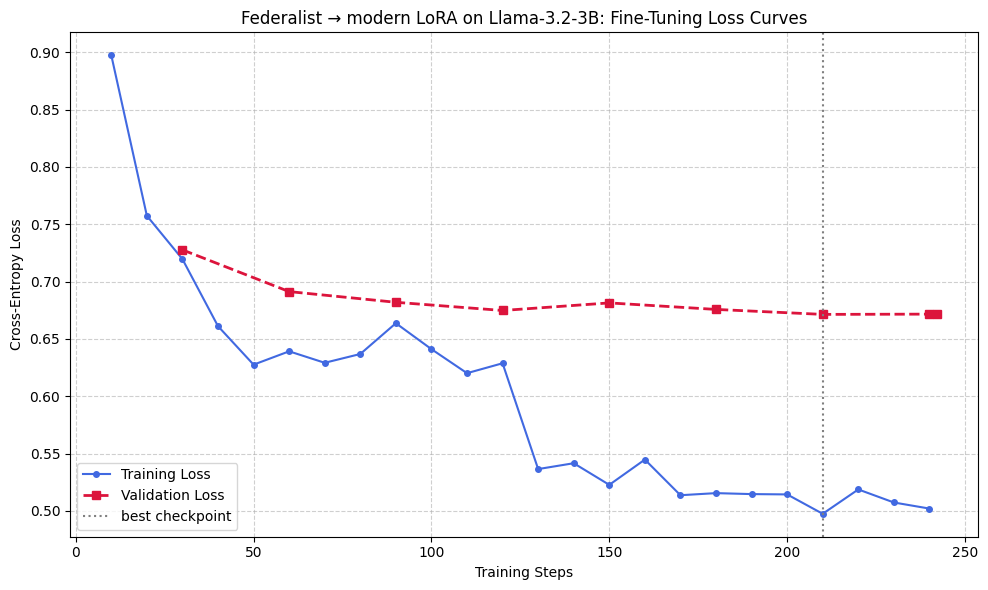

val losses: [(30, 0.7276), (60, 0.6912), (90, 0.6819), (120, 0.6747), (150, 0.6813), (180, 0.6757), (210, 0.6713), (240, 0.6716), (242, 0.6714)]  (loss values are not comparable across different base models: different tokenizers)


In [ ]:
import matplotlib.pyplot as plt

hist = trainer.state.log_history
tr = [(h["step"], h["loss"]) for h in hist if "loss" in h]
ev = [(h["step"], h["eval_loss"]) for h in hist if "eval_loss" in h]

plt.figure(figsize=(10, 6))
plt.plot(*zip(*tr), label="Training Loss", color="royalblue", marker="o", markersize=4)
plt.plot(*zip(*ev), label="Validation Loss", color="crimson", marker="s", linestyle="--", linewidth=2)
best = trainer.state.best_model_checkpoint
if best:
    plt.axvline(int(best.split("-")[-1]), color="gray", linestyle=":", label="best checkpoint")
plt.title(f"Federalist → modern LoRA on {MODEL_TITLE}: Fine-Tuning Loss Curves")
plt.xlabel("Training Steps"); plt.ylabel("Cross-Entropy Loss")
plt.legend(); plt.grid(True, linestyle="--", alpha=0.6); plt.tight_layout()
plt.savefig(OUT_DIR / "loss_curve.png", dpi=150)
plt.show()
print("val losses:", [(s, round(l, 4)) for s, l in ev], " (loss values are not comparable across different base models: different tokenizers)")
BEST_CKPT, BEST_LOSS = trainer.state.best_model_checkpoint, trainer.state.best_metric

## 6. Generate with the fine-tuned model on the held-out test chunks
Same procedure as v3: mask entities in the raw Federalist input, generate with the short training prompt, restore the names. Same decoding (temperature 0.3, top-p 0.9, repetition penalty 1.05, 450 new tokens) and seed. The notebook also counts outputs that ran to the token limit: for a freshly fine-tuned model that is the signal that it did not learn to stop.

In [ ]:
try:
    del trainer, model
except NameError:
    pass
gc.collect(); torch.cuda.empty_cache()

eval_set = test_pairs
srcs = [p["original"] for p in eval_set]
refs = [p["modern"] for p in eval_set]
ids  = [p["id"] for p in eval_set]
assert ids == V3_IDS
print(f"{len(eval_set)} held-out test chunks from papers {sorted(set(p['id'].split('_')[0] for p in eval_set))}")

from peft import PeftModel
ADAPTER_DIR = OUT_DIR / "adapter"
assert (ADAPTER_DIR / "adapter_config.json").exists(), "train the adapter first"
MAX_NEW_TOKENS = 450
norm = lambda o: re.sub(r"\s*\n+\s*", " ", o).strip()

def build_prompt(tk, system, user):
    try:
        return tk.apply_chat_template([{"role": "system", "content": system}, {"role": "user", "content": user}], tokenize=False, add_generation_prompt=True)
    except Exception:
        return tk.apply_chat_template([{"role": "user", "content": system + "\n\n" + user}], tokenize=False, add_generation_prompt=True)

@torch.no_grad()
def chat_generate(lm, tk, system, users, bs=8, temperature=EVAL_TEMPERATURE, max_new_tokens=MAX_NEW_TOKENS):
    prompts = [build_prompt(tk, system, u) for u in users]
    order = sorted(range(len(users)), key=lambda i: len(prompts[i]))
    outs, ntok = [None] * len(users), [None] * len(users)
    def run(idx):
        enc = tk([prompts[i] for i in idx], return_tensors="pt", padding=True, add_special_tokens=False).to(lm.device)
        out = lm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=True, temperature=temperature, top_p=0.9,
                          repetition_penalty=1.05, pad_token_id=tk.pad_token_id)
        L = enc["input_ids"].shape[1]
        for j, i in enumerate(idx):
            gen = out[j][L:]
            ntok[i] = int((gen != tk.pad_token_id).sum())
            outs[i] = norm(tk.decode(gen, skip_special_tokens=True))
    for s in range(0, len(order), bs):
        idx = order[s:s + bs]
        try:
            run(idx)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            for i in idx: run([i])
    return outs, ntok

def out_path(name): return OUT_DIR / ("outputs_" + re.sub(r"\W+", "_", name) + ".json")

path = out_path(FOCAL)
if path.exists() and json.loads(path.read_text(encoding="utf-8")).get("ids") == ids:
    d = json.loads(path.read_text(encoding="utf-8")); focal_out, focal_ntok = d["outputs"], d["new_tokens"]; print("loaded cached outputs for", FOCAL)
else:
    gtok = AutoTokenizer.from_pretrained(BASE_MODEL, padding_side="left")
    if gtok.pad_token is None: gtok.pad_token = gtok.eos_token
    base = AutoModelForCausalLM.from_pretrained(
        BASE_MODEL, device_map={"": 0}, torch_dtype=compute_dtype,
        quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                                               bnb_4bit_compute_dtype=compute_dtype))
    gm = PeftModel.from_pretrained(base, str(ADAPTER_DIR)); gm.eval()
    ms = [mask_input(t) for t in srcs]
    torch.manual_seed(SEED); t0 = time.time()
    raw, focal_ntok = chat_generate(gm, gtok, SYSTEM_PROMPT, [m for m, _ in ms], bs=BATCH_GEN)
    focal_out = [norm(unmask(o, surf)) for o, (_, surf) in zip(raw, ms)]
    path.write_text(json.dumps({"ids": ids, "base_model": BASE_MODEL, "outputs": focal_out, "new_tokens": focal_ntok}), encoding="utf-8")
    print(f"generated {len(focal_out)} outputs in {(time.time() - t0) / 60:.1f} min")
    del gm, base; gc.collect(); torch.cuda.empty_cache()

hit = sum(x >= MAX_NEW_TOKENS for x in focal_ntok)
print(f"outputs that ran to the {MAX_NEW_TOKENS}-token limit: {hit}/{len(focal_ntok)}" + ("   <- the model is not stopping" if hit > 3 else ""))
print("\nexample output:\n ", focal_out[0][:400])

69 held-out test chunks from papers ['fed31', 'fed40', 'fed50', 'fed59', 'fed63']


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


generated 69 outputs in 2.7 min
outputs that ran to the 450-token limit: 0/69

example output:
  In all kinds of discussions, there are certain basic truths or first principles that everything else depends on. These truths have an inner proof that, before any thinking or combining, commands our agreement. If they don't produce this effect, it must come from a flaw or disorder in how we perceive things, or from strong interests, passions, or biases. Examples of such truths include geometric ma


## 7. Assemble this family's trio
The large and small zero-shot outputs are loaded read-only from the baselines notebook; the LoRA model's outputs were generated above. Chunk ids are checked so all three were scored on the same chunks, and chat preambles are stripped from every system alike (as in the baselines notebook).

In [ ]:
SOURCES = {OWN_LARGE: BASE_DIR / "outputs_Llama_3_1_8B_zero_shot.json", OWN_ZS: BASE_DIR / "outputs_Llama_3_2_3B_zero_shot.json"}
ORDER = [OWN_LARGE, OWN_ZS, FOCAL]

raw = {}
for name, p in SOURCES.items():
    d = json.loads(p.read_text(encoding="utf-8"))
    assert d["ids"] == ids, f"{name}: chunk ids differ from this run's test chunks, cannot compare"
    raw[name] = d["outputs"]
raw[FOCAL] = focal_out

_KW = r"(?:rewrit\w*|modern|text|version|simplif\w*|paraphras\w*|translat\w*|passage|result\w*|output)"
PREAMBLE = re.compile(r"^(?:(?:sure|certainly|of course|okay|ok)\b[,!. ]*)?(?:here(?:'s| is| are)\b[^:\n]{0,80}\b" + _KW + r"\b[^:\n]{0,60}:|the (?:rewritten|modern|simplified)\b[^:\n]{0,60}:|rewritten text:|modern english:)\s*", re.I)
strip_preamble = lambda t: PREAMBLE.sub("", t, count=1).strip()

outputs, rows = {}, []
for name in ORDER:
    cleaned = [strip_preamble(t) for t in raw[name]]
    n_empty = sum(len(t.split()) == 0 for t in cleaned)
    cleaned = [t if t.split() else "." for t in cleaned]
    outputs[name] = cleaned
    rows.append({"system": name, "preamble stripped": sum(a != b for a, b in zip(raw[name], [strip_preamble(t) for t in raw[name]])), "empty outputs": n_empty,
                 "mean words": round(float(np.mean([len(t.split()) for t in cleaned])), 1),
                 "median length ratio": round(float(np.median([len(t.split()) / len(s.split()) for t, s in zip(cleaned, srcs)])), 2)})
import pandas as pd
from IPython.display import display
display(pd.DataFrame(rows).set_index("system"))

all_systems = {"source (Federalist)": srcs, "reference (cached paraphrase)": refs, **outputs}
PAIR_AGAINST = ["source (Federalist)", "reference (cached paraphrase)", OWN_LARGE, OWN_ZS]
print("\nsystems to score:", list(outputs))

,preamble stripped,empty outputs,mean words,median length ratio
system,,,,
Llama-3.1-8B zero-shot,0,0,116.2,0.77
Llama-3.2-3B zero-shot,7,0,118.9,0.77
Llama-3.2-3B fine-tuned,0,0,115.1,0.75



systems to score: ['Llama-3.1-8B zero-shot', 'Llama-3.2-3B zero-shot', 'Llama-3.2-3B fine-tuned']


## 8. Metrics (identical to v3)
The v3 metric cells, with only file names and the focal system changed. "Paired" comparisons are now *focal minus other*, where the focal model is the one fine-tuned in this notebook.

In [ ]:
from sacrebleu.metrics import BLEU
from bert_score import BERTScorer
from sentence_transformers import SentenceTransformer
import pandas as pd
from IPython.display import display

dev = "cuda"
assert ARCHAIC_LM_BASE == MODERN_LM

ctk = AutoTokenizer.from_pretrained(str(clf_dir))
clf = AutoModelForSequenceClassification.from_pretrained(str(clf_dir)).to(dev).eval()
ltok = AutoTokenizer.from_pretrained(str(alm_dir))
alm = AutoModelForCausalLM.from_pretrained(str(alm_dir)).to(dev).eval()
mlm = AutoModelForCausalLM.from_pretrained(MODERN_LM).to(dev).eval()
eval_emb = SentenceTransformer(EVAL_EMBEDDER, device=dev); eval_emb.max_seq_length = 512
bscorer = BERTScorer(model_type=BERTSCORE_MODEL, lang="en", rescale_with_baseline=False, batch_size=16, device=dev)
_bleu = BLEU(effective_order=True)

@torch.no_grad()
def clf_prob(texts, bs=16):
    out = []
    for s in range(0, len(texts), bs):
        enc = ctk(texts[s:s + bs], return_tensors="pt", padding=True, truncation=True, max_length=CLF_MAX_LEN).to(dev)
        out += torch.softmax(clf(**enc).logits.float(), -1)[:, 1].cpu().tolist()
    return np.array(out)

@torch.no_grad()
def lm_nll(lm, texts, bs=8, max_len=1000):
    res = []
    for s in range(0, len(texts), bs):
        enc = [[ltok.bos_token_id] + ltok(t, add_special_tokens=False)["input_ids"][:max_len - 1] for t in texts[s:s + bs]]
        L = max(map(len, enc))
        ids_ = torch.tensor([e + [ltok.eos_token_id] * (L - len(e)) for e in enc]).to(dev)
        att = torch.tensor([[1] * len(e) + [0] * (L - len(e)) for e in enc]).to(dev)
        logits = lm(input_ids=ids_, attention_mask=att).logits[:, :-1].float()
        tgt, m = ids_[:, 1:], att[:, 1:].float()
        nll = torch.nn.functional.cross_entropy(logits.reshape(-1, logits.size(-1)), tgt.reshape(-1), reduction="none").view(tgt.shape)
        res += ((nll * m).sum(1) / m.sum(1)).cpu().tolist()
    return np.array(res)

def cos_pairs(a, b):
    ea = eval_emb.encode(a, batch_size=32, convert_to_tensor=True, normalize_embeddings=True, show_progress_bar=False)
    eb = eval_emb.encode(b, batch_size=32, convert_to_tensor=True, normalize_embeddings=True, show_progress_bar=False)
    return (ea * eb).sum(1).cpu().numpy()

def sari_items(src_, preds, refs_):
    return np.array([_sari.compute(sources=[s], predictions=[p], references=[[r]])["sari"] for s, p, r in zip(src_, preds, refs_)])

ARTIFACT = re.compile(r"\[[A-Z]+(?:_\d+)?\]|(?:^|\n|:\s*)[-•*]\s+\S")
nwords = lambda t: len(t.split())
NAN = np.full(len(eval_set), np.nan)

def score_system(name, texts):
    is_src, is_ref = name.startswith("source"), name.startswith("reference")
    M = {}
    pm = clf_prob(texts); M["clf_p_modern"] = pm; M["clf_is_modern"] = (pm > 0.5).astype(float)
    na, nm = lm_nll(alm, texts), lm_nll(mlm, texts)
    M["ppl_logratio"] = na - nm
    M["ppl_modern"] = np.exp(nm)
    M["bleu_src"] = NAN if is_src else np.array([_bleu.sentence_score(t, [s]).score for t, s in zip(texts, srcs)])
    M["bleu_ref"] = NAN if is_ref else np.array([_bleu.sentence_score(t, [r]).score for t, r in zip(texts, refs)])
    M["bertscore_src"] = NAN if is_src else bscorer.score(texts, srcs)[2].numpy()
    M["bertscore_ref"] = NAN if is_ref else bscorer.score(texts, refs)[2].numpy()
    M["cos_src"] = NAN if is_src else cos_pairs(texts, srcs)
    M["cos_ref"] = NAN if is_ref else cos_pairs(texts, refs)
    M["sari"] = NAN if is_ref else sari_items(srcs, texts, refs)
    M["len_ratio_src"] = NAN if is_src else np.array([nwords(t) / max(1, nwords(s)) for t, s in zip(texts, srcs)])
    M["len_ratio_ref"] = NAN if is_ref else np.array([nwords(t) / max(1, nwords(r)) for t, r in zip(texts, refs)])
    M["artifact"] = np.array([float(bool(ARTIFACT.search(t))) for t in texts])
    return M

all_systems = {"source (Federalist)": srcs, "reference (cached paraphrase)": refs, **outputs}
PER = {}
for name, texts in all_systems.items():
    t0 = time.time(); PER[name] = score_system(name, texts); print(f"  scored {name} ({time.time() - t0:.0f}s)")

long_df = pd.DataFrame([{"system": s, "id": ids[i], **{k: float(v[i]) for k, v in M.items()}} for s, M in PER.items() for i in range(len(ids))])
long_df.to_csv(OUT_DIR / "per_chunk_metrics.csv", index=False)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

... (20 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  scored source (Federalist) (10s)
  scored reference (cached paraphrase) (4s)
  scored Llama-3.1-8B zero-shot (8s)
  scored Llama-3.2-3B zero-shot (7s)
  scored Llama-3.2-3B fine-tuned (7s)


In [ ]:
def boot_ci(v, tf=None):
    v = np.asarray(v, float); v = v[~np.isnan(v)]
    if len(v) == 0: return None
    rng = np.random.default_rng(SEED)
    means = v[rng.integers(0, len(v), (N_BOOT, len(v)))].mean(1)
    lo, hi = np.percentile(means, [2.5, 97.5]); m = v.mean()
    return (tf(m), tf(lo), tf(hi)) if tf else (m, lo, hi)

def fmt(v, tf=None, pct=False, nd=3):
    r = boot_ci(v, tf)
    if r is None: return "–"
    m, lo, hi = r
    if pct: return f"{100*m:.0f}%  [{100*lo:.0f}, {100*hi:.0f}]"
    return f"{m:.{nd}f}  [{lo:.{nd}f}, {hi:.{nd}f}]"

GROUPS = {
    "Style transfer strength (higher = more modern)": [("clf_is_modern", "classifier acc", dict(pct=True)),
                                                        ("clf_p_modern", "mean P(modern)", {}),
                                                        ("ppl_logratio", "PPL ratio arch/mod (geo-mean)", dict(tf=np.exp, nd=2))],
    "Content preservation (higher = better)": [("bleu_src", "self-BLEU (vs source)", dict(nd=1)), ("bleu_ref", "BLEU (vs ref)", dict(nd=1)),
                                                ("bertscore_src", "BERTScore F1 (vs source)", {}), ("bertscore_ref", "BERTScore F1 (vs ref)", {}),
                                                ("cos_src", "cosine (vs source)", {}), ("cos_ref", "cosine (vs ref)", {})],
    "Simplicity": [("sari", "SARI", dict(nd=1)), ("len_ratio_src", "length ratio out/source", dict(nd=2)), ("len_ratio_ref", "length ratio out/ref", dict(nd=2))],
    "Sanity": [("ppl_modern", "PPL under modern LM (lower = more fluent)", dict(nd=1)), ("artifact", "artifact rate", dict(pct=True))],
}
numeric_rows = []
for title, cols in GROUPS.items():
    tab = {name: {label: fmt(PER[name][k], **kw) for k, label, kw in cols} for name in PER}
    print("\n" + title); display(pd.DataFrame(tab).T)
for name, M in PER.items():
    for k, v in M.items():
        r = boot_ci(v)
        numeric_rows.append({"system": name, "metric": k, "mean": None if r is None else r[0], "ci_lo": None if r is None else r[1], "ci_hi": None if r is None else r[2]})
pd.DataFrame(numeric_rows).to_csv(OUT_DIR / "eval_table.csv", index=False)

src_acc = float(np.nanmean(PER["source (Federalist)"]["clf_is_modern"])); ref_acc = float(np.nanmean(PER["reference (cached paraphrase)"]["clf_is_modern"]))
print(f"\nCALIBRATION: classifier says {100*src_acc:.0f}% of Federalist sources and {100*ref_acc:.0f}% of reference paraphrases are 'modern'.")
if src_acc > 0.1 or ref_acc < 0.8:
    print("  -> The classifier is not cleanly separating the two calibration rows. Treat its numbers with caution.")

PAIRED = [("clf_p_modern", "P(modern)"), ("ppl_logratio", "log PPL ratio"), ("bertscore_src", "BERTScore vs source"), ("bertscore_ref", "BERTScore vs ref"),
          ("cos_src", "cosine vs source"), ("cos_ref", "cosine vs ref"), ("bleu_ref", "BLEU vs ref"), ("sari", "SARI")]
print("\nPAIRED COMPARISON  (focal minus other; positive = focal higher; CI over chunks)")
for other in [s for s in outputs if s != FOCAL and s in PAIR_AGAINST]:
    print(f"\n  {FOCAL} vs {other}")
    for k, label in PAIRED:
        d = PER[FOCAL][k] - PER[other][k]
        m, lo, hi = boot_ci(d)
        sig = "  <- CI excludes 0" if (lo > 0 or hi < 0) else ""
        print(f"    {label:22s} diff {m:+.3f}  [{lo:+.3f}, {hi:+.3f}]  focal higher on {int((d > 0).sum())}/{len(d)} chunks{sig}")

worst = np.argsort(PER[FOCAL]["bertscore_src"])[:3]
for i in worst:
    print(f"\n--- chunk {ids[i]}: focal BERTScore vs source {PER[FOCAL]['bertscore_src'][i]:.3f}")
    print("SOURCE: ", srcs[i][:350]); print("REF:    ", refs[i][:350])
    for s in outputs: print(f"{s[:22]:22s}", outputs[s][i][:350])


Style transfer strength (higher = more modern)


,classifier acc,mean P(modern),PPL ratio arch/mod (geo-mean)
source (Federalist),"0% [0, 0]","0.000 [0.000, 0.000]","0.74 [0.72, 0.76]"
reference (cached paraphrase),"67% [55, 77]","0.673 [0.565, 0.775]","1.09 [1.04, 1.14]"
Llama-3.1-8B zero-shot,"90% [83, 97]","0.897 [0.823, 0.968]","1.24 [1.20, 1.28]"
Llama-3.2-3B zero-shot,"83% [72, 91]","0.820 [0.723, 0.907]","1.17 [1.13, 1.21]"
Llama-3.2-3B fine-tuned,"67% [55, 78]","0.659 [0.547, 0.772]","1.07 [1.03, 1.11]"



Content preservation (higher = better)


,self-BLEU (vs source),BLEU (vs ref),BERTScore F1 (vs source),BERTScore F1 (vs ref),cosine (vs source),cosine (vs ref)
source (Federalist),–,"18.5 [16.1, 21.3]",–,"0.905 [0.900, 0.911]",–,"0.843 [0.825, 0.860]"
reference (cached paraphrase),"17.5 [15.1, 20.3]",–,"0.905 [0.900, 0.911]",–,"0.843 [0.825, 0.860]",–
Llama-3.1-8B zero-shot,"10.7 [9.3, 12.3]","23.9 [21.7, 26.2]","0.895 [0.892, 0.899]","0.924 [0.921, 0.928]","0.782 [0.761, 0.803]","0.875 [0.859, 0.889]"
Llama-3.2-3B zero-shot,"14.3 [11.9, 16.8]","21.8 [19.5, 24.1]","0.899 [0.894, 0.904]","0.921 [0.917, 0.924]","0.811 [0.790, 0.831]","0.871 [0.856, 0.886]"
Llama-3.2-3B fine-tuned,"21.1 [17.7, 25.1]","31.5 [28.5, 34.5]","0.911 [0.905, 0.916]","0.931 [0.927, 0.935]","0.864 [0.844, 0.883]","0.891 [0.875, 0.906]"



Simplicity


,SARI,length ratio out/source,length ratio out/ref
source (Federalist),"44.7 [43.7, 45.9]",–,"1.41 [1.36, 1.46]"
reference (cached paraphrase),–,"0.73 [0.70, 0.75]",–
Llama-3.1-8B zero-shot,"51.3 [49.4, 52.9]","0.77 [0.74, 0.79]","1.07 [1.03, 1.12]"
Llama-3.2-3B zero-shot,"50.7 [49.0, 52.4]","0.79 [0.75, 0.83]","1.10 [1.05, 1.15]"
Llama-3.2-3B fine-tuned,"56.5 [54.6, 58.4]","0.75 [0.73, 0.78]","1.05 [1.01, 1.09]"



Sanity


,PPL under modern LM (lower = more fluent),artifact rate
source (Federalist),"35.0 [32.3, 38.0]","0% [0, 0]"
reference (cached paraphrase),"34.0 [31.2, 36.9]","0% [0, 0]"
Llama-3.1-8B zero-shot,"32.1 [29.5, 34.9]","0% [0, 0]"
Llama-3.2-3B zero-shot,"30.4 [28.1, 32.9]","0% [0, 0]"
Llama-3.2-3B fine-tuned,"34.1 [31.4, 37.0]","0% [0, 0]"



CALIBRATION: classifier says 0% of Federalist sources and 67% of reference paraphrases are 'modern'.
  -> The classifier is not cleanly separating the two calibration rows. It may be keying on topic or genre instead of style; treat its numbers with caution (see the note at the top).

PAIRED COMPARISON  (focal minus other; positive = focal higher; CI over chunks)

  Llama-3.2-3B fine-tuned vs Llama-3.1-8B zero-shot
    P(modern)              diff -0.238  [-0.349, -0.133]  focal higher on 12/69 chunks  <- CI excludes 0
    log PPL ratio          diff -0.147  [-0.184, -0.109]  focal higher on 11/69 chunks  <- CI excludes 0
    BERTScore vs source    diff +0.015  [+0.010, +0.021]  focal higher on 48/69 chunks  <- CI excludes 0
    BERTScore vs ref       diff +0.007  [+0.004, +0.010]  focal higher on 48/69 chunks  <- CI excludes 0
    cosine vs source       diff +0.082  [+0.059, +0.103]  focal higher on 56/69 chunks  <- CI excludes 0
    cosine vs ref          diff +0.016  [-0.004, +0.035]

### Readability, sentence-level NLI, and joint pass rate

In [ ]:
def split_sentences(t):
    return re.split(r"(?<=[.!?])\s+(?=[A-Z\"'(])", t.strip())

In [ ]:
def count_syl(w):
    w = re.sub(r"[^a-z]", "", w.lower())
    if not w: return 0
    n = len(re.findall(r"[aeiouy]+", w))
    if w.endswith("e") and not w.endswith(("le", "ee")) and n > 1: n -= 1
    if w.endswith("ed") and not re.search(r"[td]ed$", w) and n > 1: n -= 1
    return max(1, n)

def readability(text):
    sents = [s for s in split_sentences(text) if s.strip()] or [text]
    words = re.findall(r"[A-Za-z']+", text)
    if not words: return (np.nan,) * 4
    syl = [count_syl(w) for w in words]
    wps, spw = len(words) / len(sents), sum(syl) / len(words)
    return (0.39 * wps + 11.8 * spw - 15.59,
            wps,
            spw,
            100 * float(np.mean([x >= 3 for x in syl])))

for name, texts in all_systems.items():
    R = np.array([readability(t) for t in texts])
    PER[name].update(fkgl=R[:, 0], sent_len=R[:, 1], syl_per_word=R[:, 2], complex_pct=R[:, 3])

tab = {n: {"FKGL grade": fmt(PER[n]["fkgl"], nd=1), "words/sentence": fmt(PER[n]["sent_len"], nd=1),
           "syllables/word": fmt(PER[n]["syl_per_word"], nd=2), "% complex words": fmt(PER[n]["complex_pct"], nd=1)} for n in PER}
print("Readability (lower = easier). Compare rows, not absolute grades.")
display(pd.DataFrame(tab).T)

print("\nPAIRED: FKGL, focal minus other (negative = focal is easier)")
for other in [s for s in PER if s != FOCAL and s in PAIR_AGAINST]:
    d = PER[FOCAL]["fkgl"] - PER[other]["fkgl"]; m, lo, hi = boot_ci(d)
    print(f"  vs {other:32s} {m:+.2f}  [{lo:+.2f}, {hi:+.2f}]" + ("   <- CI excludes 0" if (lo > 0 or hi < 0) else ""))

Readability (lower = easier). FKGL uses a heuristic syllable counter, so compare rows, not absolute grades.


,FKGL grade,words/sentence,syllables/word,% complex words
source (Federalist),"20.5 [18.8, 22.4]","42.6 [38.4, 47.5]","1.65 [1.63, 1.67]","19.4 [18.6, 20.1]"
reference (cached paraphrase),"13.3 [12.4, 14.2]","24.2 [22.2, 26.6]","1.64 [1.62, 1.67]","18.0 [17.0, 19.1]"
Llama-3.1-8B zero-shot,"14.1 [13.3, 15.1]","26.4 [24.4, 28.6]","1.64 [1.62, 1.67]","18.2 [17.3, 19.3]"
Llama-3.2-3B zero-shot,"16.6 [15.4, 17.9]","31.2 [28.3, 34.4]","1.70 [1.68, 1.73]","20.2 [19.1, 21.2]"
Llama-3.2-3B fine-tuned,"13.6 [12.6, 14.8]","24.8 [22.3, 27.8]","1.65 [1.63, 1.67]","18.3 [17.4, 19.2]"



PAIRED: FKGL, focal minus other (negative = focal is easier)
  vs source (Federalist)              -6.94  [-8.54, -5.50]   <- CI excludes 0
  vs reference (cached paraphrase)    +0.32  [-0.69, +1.36]
  vs Llama-3.1-8B zero-shot           -0.52  [-1.67, +0.67]
  vs Llama-3.2-3B zero-shot           -3.06  [-4.57, -1.76]   <- CI excludes 0

Caution: FKGL falls when sentences are chopped short, with no change in vocabulary. Read it next to '% complex words'.


In [ ]:
NLI_NAME = "roberta-large-mnli"
ntok = AutoTokenizer.from_pretrained(NLI_NAME)
nli = AutoModelForSequenceClassification.from_pretrained(NLI_NAME).to(dev).eval()
id2l = {int(k): v.lower() for k, v in nli.config.id2label.items()}
iE = next(k for k, v in id2l.items() if v.startswith("entail")); iC = next(k for k, v in id2l.items() if v.startswith("contra"))
print("NLI labels:", id2l)

@torch.no_grad()
def nli_probs(prem, hyp, bs=32):
    E, C = [], []
    for s in range(0, len(prem), bs):
        enc = ntok(prem[s:s + bs], hyp[s:s + bs], return_tensors="pt", padding=True, truncation="only_first", max_length=400).to(dev)
        with torch.autocast("cuda", dtype=torch.float16):
            p = torch.softmax(nli(**enc).logits.float(), -1)
        E += p[:, iE].cpu().tolist(); C += p[:, iC].cpu().tolist()
    return np.array(E), np.array(C)

def windows(sents): return sents + [sents[i] + " " + sents[i + 1] for i in range(len(sents) - 1)]

def best_support(prem_sents, hyp_sents):
    W = windows(prem_sents)
    pairs = [(w, h) for h in hyp_sents for w in W]
    E, C = nli_probs([p for p, _ in pairs], [h for _, h in pairs])
    E, C = E.reshape(len(hyp_sents), len(W)), C.reshape(len(hyp_sents), len(W))
    return E.max(1), C.max(1), E.argmax(1)

def nli_chunk(src_text, out_text):
    ss, oo = split_sentences(src_text), split_sentences(out_text)
    if not ss or not oo: return [np.nan] * 5, None
    Eo, Co, arg = best_support(ss, oo)
    Es, _, _ = best_support(oo, ss)
    contra = float(np.mean((Eo < 0.5) & (Co > 0.5)))
    return [float(Eo.mean()), float((Eo >= 0.5).mean()), float(Es.mean()), float((Es >= 0.5).mean()), contra], (oo, Eo, arg, windows(ss))

NLI_ROWS = ["reference (cached paraphrase)", *outputs]
detail = {}
for name in PER:
    if name not in NLI_ROWS:
        for k in ("nli_faith", "faith_frac", "nli_cover", "cover_frac", "nli_contra"): PER[name][k] = np.full(len(ids), np.nan)
        continue
    t0 = time.time(); rows, detail[name] = [], []
    for i in range(len(ids)):
        r, d = nli_chunk(srcs[i], all_systems[name][i]); rows.append(r); detail[name].append(d)
    R = np.array(rows)
    for j, k in enumerate(("nli_faith", "faith_frac", "nli_cover", "cover_frac", "nli_contra")):
        PER[name][k] = R[:, j]
    print(f"  NLI scored {name} ({(time.time() - t0) / 60:.1f} min)")
del nli; gc.collect(); torch.cuda.empty_cache()

tab = {n: {"faithfulness (mean best-entail)": fmt(PER[n]["nli_faith"]), "% output sentences supported": fmt(PER[n]["faith_frac"], pct=True),
           "coverage (mean best-entail)": fmt(PER[n]["nli_cover"]), "% source sentences covered": fmt(PER[n]["cover_frac"], pct=True),
           "% output sentences contradicted": fmt(PER[n]["nli_contra"], pct=True)} for n in NLI_ROWS}
display(pd.DataFrame(tab).T)

print("\nPAIRED (focal minus other; positive = focal higher; for 'contradicted' lower is better)")
for other in [s for s in NLI_ROWS if s != FOCAL and s in PAIR_AGAINST]:
    print(f"\n  {FOCAL} vs {other}")
    for k, label in [("nli_faith", "faithfulness"), ("faith_frac", "% sentences supported"), ("nli_cover", "coverage"), ("cover_frac", "% source covered"), ("nli_contra", "% contradicted")]:
        d = PER[FOCAL][k] - PER[other][k]; m, lo, hi = boot_ci(d)
        print(f"    {label:24s} {m:+.3f}  [{lo:+.3f}, {hi:+.3f}]" + ("   <- CI excludes 0" if (lo > 0 or hi < 0) else ""))

cand = [(Eo[j], i, j) for i, d in enumerate(detail[FOCAL]) if d is not None for j, _ in enumerate(d[0]) for Eo in [d[1]]]
print("\nLEAST-SUPPORTED OUTPUT SENTENCES OF THE FOCAL MODEL:")
for e, i, j in sorted(cand)[:8]:
    oo, Eo, arg, W = detail[FOCAL][i]
    print(f"\n  chunk {ids[i]} | support {e:.2f}\n    OUTPUT: {oo[j][:260]}\n    BEST SOURCE WINDOW: {W[arg[j]][:300]}")

config.json:   0%|          | 0.00/688 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.43GB            

... (2 outputs left out)

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-large-mnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


NLI labels: {0: 'contradiction', 1: 'neutral', 2: 'entailment'}
  NLI scored reference (cached paraphrase) (0.3 min)
  NLI scored Llama-3.1-8B zero-shot (0.3 min)
  NLI scored Llama-3.2-3B zero-shot (0.3 min)
  NLI scored Llama-3.2-3B fine-tuned (0.3 min)


,faithfulness (mean best-entail),% output sentences supported,coverage (mean best-entail),% source sentences covered,% output sentences contradicted
reference (cached paraphrase),"0.943 [0.926, 0.958]","97% [96, 99]","0.765 [0.716, 0.806]","81% [74, 86]","1% [0, 2]"
Llama-3.1-8B zero-shot,"0.920 [0.891, 0.943]","94% [90, 97]","0.801 [0.757, 0.840]","84% [78, 89]","3% [0, 7]"
Llama-3.2-3B zero-shot,"0.894 [0.863, 0.921]","92% [88, 95]","0.811 [0.772, 0.848]","86% [81, 91]","2% [1, 4]"
Llama-3.2-3B fine-tuned,"0.943 [0.927, 0.958]","97% [95, 99]","0.781 [0.743, 0.817]","83% [78, 87]","1% [0, 3]"



PAIRED (focal minus other; positive = focal higher; for 'contradicted' lower is better)

  Llama-3.2-3B fine-tuned vs reference (cached paraphrase)
    faithfulness             -0.000  [-0.018, +0.019]
    % sentences supported    -0.006  [-0.030, +0.018]
    coverage                 +0.016  [-0.036, +0.070]
    % source covered         +0.023  [-0.050, +0.103]
    % contradicted           -0.000  [-0.015, +0.015]

  Llama-3.2-3B fine-tuned vs Llama-3.1-8B zero-shot
    faithfulness             +0.023  [-0.005, +0.057]
    % sentences supported    +0.026  [-0.014, +0.072]
    coverage                 -0.020  [-0.068, +0.033]
    % source covered         -0.009  [-0.070, +0.057]
    % contradicted           -0.018  [-0.058, +0.013]

  Llama-3.2-3B fine-tuned vs Llama-3.2-3B zero-shot
    faithfulness             +0.049  [+0.022, +0.080]   <- CI excludes 0
    % sentences supported    +0.049  [+0.013, +0.088]   <- CI excludes 0
    coverage                 -0.030  [-0.077, +0.017]
    %

In [ ]:
THR = dict(p_modern=0.5,
           faith_frac=0.75,
           cover_frac=0.75,
           fkgl_drop=2.0,
           ppl_mult=1.5)
ppl_cap = THR["ppl_mult"] * np.median(PER["reference (cached paraphrase)"]["ppl_modern"])
print(f"fluency cap: PPL under modern LM <= {ppl_cap:.1f}\n")

def criteria(name):
    M = PER[name]
    return {"modern": M["clf_p_modern"] > THR["p_modern"],
            "faithful": M["faith_frac"] >= THR["faith_frac"],
            "complete": M["cover_frac"] >= THR["cover_frac"],
            "simpler": (PER["source (Federalist)"]["fkgl"] - M["fkgl"]) >= THR["fkgl_drop"],
            "fluent": M["ppl_modern"] <= ppl_cap,
            "no artifacts": M["artifact"] == 0}

JOINT = {}
rows = {}
for name in NLI_ROWS:
    c = criteria(name); joint = np.all(np.stack(list(c.values())), axis=0).astype(float); JOINT[name] = joint; PER[name]["joint_pass"] = joint
    rows[name] = {**{k: fmt(v.astype(float), pct=True) for k, v in c.items()}, "ALL (joint pass)": fmt(joint, pct=True)}
print("Share of chunks passing each criterion, and all of them together:")
display(pd.DataFrame(rows).T)

print("\nPAIRED: joint pass, focal minus other")
for other in [s for s in NLI_ROWS if s != FOCAL and s in PAIR_AGAINST]:
    d = JOINT[FOCAL] - JOINT[other]; m, lo, hi = boot_ci(d)
    print(f"  vs {other:32s} {100*m:+.0f} pts  [{100*lo:+.0f}, {100*hi:+.0f}]" + ("   <- CI excludes 0" if (lo > 0 or hi < 0) else ""))

fluency cap: PPL under modern LM <= 48.1

Share of chunks passing each criterion, and all of them together:


,modern,faithful,complete,simpler,fluent,no artifacts,ALL (joint pass)
reference (cached paraphrase),"67% [55, 77]","99% [96, 100]","71% [59, 81]","81% [71, 90]","90% [83, 97]","100% [100, 100]","33% [22, 45]"
Llama-3.1-8B zero-shot,"90% [83, 97]","91% [84, 97]","72% [61, 83]","77% [67, 86]","93% [86, 99]","100% [100, 100]","46% [35, 58]"
Llama-3.2-3B zero-shot,"83% [72, 91]","81% [72, 90]","77% [67, 87]","59% [48, 71]","96% [90, 100]","100% [100, 100]","32% [22, 43]"
Llama-3.2-3B fine-tuned,"67% [55, 78]","96% [90, 100]","71% [59, 81]","83% [72, 91]","90% [83, 96]","100% [100, 100]","35% [23, 46]"


The 'reference' row shows what is achievable with these thresholds. If even it scores low, a threshold is too strict.

PAIRED: joint pass, focal minus other
  vs reference (cached paraphrase)    +1 pts  [-12, +14]
  vs Llama-3.1-8B zero-shot           -12 pts  [-25, +1]
  vs Llama-3.2-3B zero-shot           +3 pts  [-10, +16]


## 9. This family's trio: large zero-shot vs small zero-shot vs small + LoRA
Three tables:
1. **Means** of the main metrics for the three models.
2. **Paired contrasts** with 95% intervals over the 69 chunks. A ✓ marks a significant change in the *desirable* direction and a ✗ in the undesirable one; no mark means the interval includes 0 (indistinguishable here, which is not the same as equal). Length ratio has no preferred direction, so it carries no mark.
3. **Gap closed**: for metrics where the large model is significantly different from the small one, the share of that gap that LoRA closes, `(LoRA − small) / (large − small)`. 100% means the LoRA model reaches the large model's level, 0% means no change, above 100% means it overshoots, and negative means it moved the wrong way.

A scorecard counts the significant ✓ and ✗ per contrast, and a figure shows four headline metrics for the three models. With about 12 metrics per contrast, expect a stray interval to exclude 0 by chance: look for patterns that repeat across several metrics.


LLAMA:  large = Llama-3.1-8B zero-shot  |  small = Llama-3.2-3B zero-shot  |  small + LoRA = Llama-3.2-3B fine-tuned

1. MEANS


,large,small,small + LoRA
classifier % modern,90,83,67
log PPL ratio (arch/mod),0.214,0.156,0.066
BERTScore vs source,0.895,0.899,0.911
cosine vs source,0.782,0.811,0.864
% sentences supported (NLI),94,92,97
% source sentences covered (NLI),84,86,83
% sentences contradicted,3.0,2.5,1.2
FKGL grade (lower = easier),14.1,16.6,13.6
% complex words (lower = simpler),18.2,20.2,18.3
length ratio out/source,0.77,0.79,0.75



2. PAIRED CONTRASTS (value [95% CI]; units as in table 1; ✓ significantly better, ✗ significantly worse)


,SIZE: large - small,FINE-TUNING: LoRA - small,GAP: LoRA - large
classifier % modern,"+7 [-1, +16]","-16 [-28, -6] ✗","-23 [-35, -13] ✗"
log PPL ratio (arch/mod),"+0.057 [+0.026, +0.088] ✓","-0.090 [-0.126, -0.055] ✗","-0.147 [-0.184, -0.109] ✗"
BERTScore vs source,"-0.004 [-0.008, +0.001]","+0.012 [+0.006, +0.018] ✓","+0.015 [+0.010, +0.021] ✓"
cosine vs source,"-0.028 [-0.046, -0.010] ✗","+0.054 [+0.033, +0.075] ✓","+0.082 [+0.059, +0.103] ✓"
% sentences supported (NLI),"+2 [-3, +7]","+5 [+1, +9] ✓","+3 [-1, +7]"
% source sentences covered (NLI),"-2 [-8, +4]","-3 [-9, +3]","-1 [-7, +6]"
% sentences contradicted,"+0.5 [-2.9, +4.7]","-1.3 [-3.5, +0.8]","-1.8 [-5.8, +1.3]"
FKGL grade (lower = easier),"-2.5 [-3.6, -1.6] ✓","-3.1 [-4.6, -1.8] ✓","-0.5 [-1.7, +0.7]"
% complex words (lower = simpler),"-1.9 [-2.8, -0.9] ✓","-1.9 [-2.9, -0.9] ✓","+0.1 [-0.9, +1.0]"
length ratio out/source,"-0.02 [-0.06, +0.01]","-0.04 [-0.08, -0.00]","-0.01 [-0.04, +0.02]"


3. SHARE OF THE LARGE-vs-SMALL GAP THAT LoRA CLOSES (only where the large model is significantly different from the small one)


,gap closed
classifier % modern,n/a (no significant size gap)
log PPL ratio (arch/mod),-156%
BERTScore vs source,n/a (no significant size gap)
cosine vs source,-188%
% sentences supported (NLI),n/a (no significant size gap)
% source sentences covered (NLI),n/a (no significant size gap)
% sentences contradicted,n/a (no significant size gap)
FKGL grade (lower = easier),121%
% complex words (lower = simpler),97%
length ratio out/source,n/a (no significant size gap)



SCORECARD: number of significant improvements (✓) / deteriorations (✗) among the directional metrics


,Llama
SIZE (large vs small),4 ✓ / 1 ✗
FINE-TUNING (LoRA vs small),6 ✓ / 2 ✗
GAP (LoRA vs large; ✓ = LoRA better),3 ✓ / 2 ✗


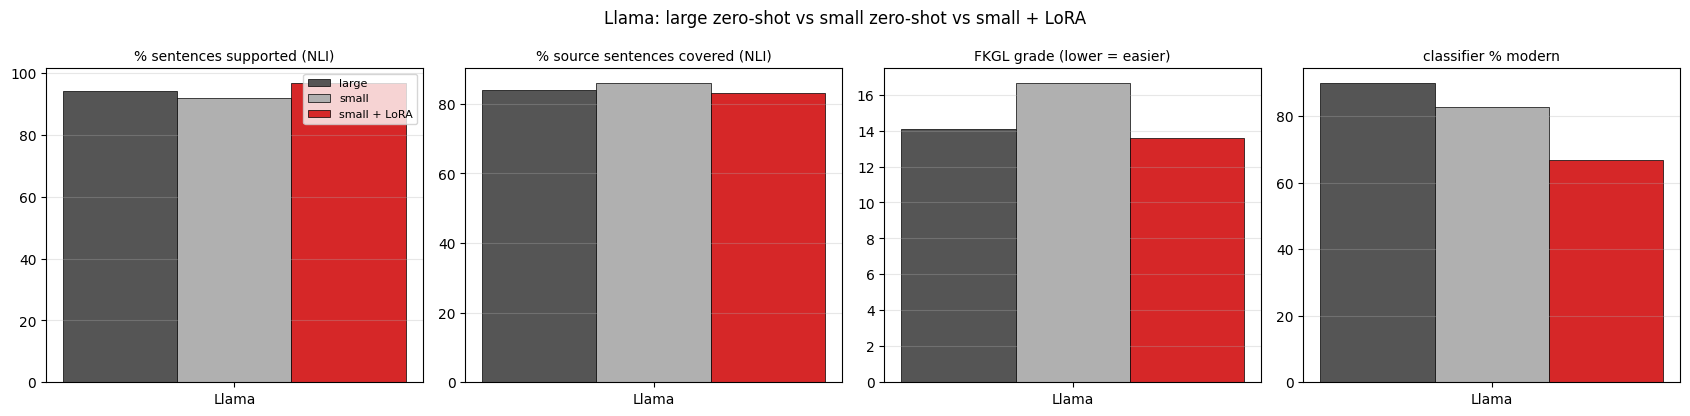

In [ ]:
MY_FAMILY = "Llama"
TRIADS = {MY_FAMILY: (OWN_LARGE, OWN_ZS, FOCAL)}
TM = [
    ("clf_is_modern", "classifier % modern", +1, 100, 0), ("ppl_logratio", "log PPL ratio (arch/mod)", +1, 1, 3),
    ("bertscore_src", "BERTScore vs source", +1, 1, 3), ("cos_src", "cosine vs source", +1, 1, 3),
    ("faith_frac", "% sentences supported (NLI)", +1, 100, 0), ("cover_frac", "% source sentences covered (NLI)", +1, 100, 0),
    ("nli_contra", "% sentences contradicted", -1, 100, 1), ("fkgl", "FKGL grade (lower = easier)", -1, 1, 1),
    ("complex_pct", "% complex words (lower = simpler)", -1, 1, 1), ("len_ratio_src", "length ratio out/source", 0, 1, 2),
    ("sari", "SARI (reference-biased toward Qwen)", +1, 1, 1), ("joint_pass", "joint pass % (all criteria)", +1, 100, 0)]

def _mean(sys_, k): return float(np.nanmean(np.asarray(PER[sys_][k], float)))
def _contrast(a, b, k, sign, scale, nd):
    d = (np.asarray(PER[a][k], float) - np.asarray(PER[b][k], float))
    if np.isnan(d).all(): return "n/a", 0, 0
    m, lo, hi = boot_ci(d); sig = lo > 0 or hi < 0
    good = sig and sign != 0 and np.sign(m) == sign; bad = sig and sign != 0 and np.sign(m) != sign
    return f"{m*scale:+.{nd}f} [{lo*scale:+.{nd}f}, {hi*scale:+.{nd}f}]" + (" ✓" if good else " ✗" if bad else ""), int(good), int(bad), sig, m

SCORE, TRIAD_TABLES = {}, {}
def triad(fam):
    L, S, F = TRIADS[fam]
    if not all(x in PER for x in (L, S, F)):
        print(f"\n[{fam}] skipped: missing", [x for x in (L, S, F) if x not in PER]); return
    print("\n" + "=" * 100 + f"\n{fam.upper()}:  large = {L}  |  small = {S}  |  small + LoRA = {F}\n" + "=" * 100)
    means = {label: {"large": f"{_mean(L,k)*sc:.{nd}f}", "small": f"{_mean(S,k)*sc:.{nd}f}", "small + LoRA": f"{_mean(F,k)*sc:.{nd}f}"} for k, label, sg, sc, nd in TM if k in PER[L] and k in PER[S] and k in PER[F]}
    print("\n1. MEANS"); display(pd.DataFrame(means).T)
    con, tally = {}, {"size": [0, 0], "finetune": [0, 0], "vs_large": [0, 0]}; gap = {}
    for k, label, sg, sc, nd in TM:
        if not all(k in PER[x] for x in (L, S, F)): continue
        size = _contrast(L, S, k, sg, sc, nd); ft = _contrast(F, S, k, sg, sc, nd); vl = _contrast(F, L, k, sg, sc, nd)
        con[label] = {"SIZE: large - small": size[0], "FINE-TUNING: LoRA - small": ft[0], "GAP: LoRA - large": vl[0]}
        for name, r in (("size", size), ("finetune", ft), ("vs_large", vl)):
            if len(r) > 3: tally[name][0] += r[1]; tally[name][1] += r[2]
        den = _mean(L, k) - _mean(S, k)
        gap[label] = f"{100 * (_mean(F, k) - _mean(S, k)) / den:.0f}%" if len(size) > 3 and size[3] and abs(den) > 1e-9 else "n/a"
    print("\n2. PAIRED CONTRASTS")
    display(pd.DataFrame(con).T)
    print("3. SHARE OF THE GAP CLOSED")
    display(pd.DataFrame({"gap closed": gap}))
    SCORE[fam] = tally; TRIAD_TABLES[fam] = {"means": means, "contrasts": con, "gap_closed": gap}

order = [MY_FAMILY]
triad(MY_FAMILY)

print("\n" + "=" * 100 + "\nSCORECARD\n" + "=" * 100)
display(pd.DataFrame({fam: {"SIZE": f"{t['size'][0]} ✓ / {t['size'][1]} ✗", "FINE-TUNING": f"{t['finetune'][0]} ✓ / {t['finetune'][1]} ✗",
                            "GAP": f"{t['vs_large'][0]} ✓ / {t['vs_large'][1]} ✗"} for fam, t in SCORE.items()}))

import matplotlib.pyplot as plt
fams = [f for f in order if f in SCORE]
PANELS = [("faith_frac", "% sentences supported (NLI)", 100), ("cover_frac", "% source sentences covered (NLI)", 100), ("fkgl", "FKGL grade (lower = easier)", 1), ("clf_is_modern", "classifier % modern", 100)]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, (k, title, sc) in zip(axes, PANELS):
    for j, (role, color) in enumerate((("large", "#555555"), ("small", "#b0b0b0"), ("small + LoRA", "#d62728"))):
        vals = [_mean(TRIADS[f][j], k) * sc for f in fams]
        ax.bar(np.arange(len(fams)) + (j - 1) * 0.27, vals, 0.27, color=color, label=role, edgecolor="k", linewidth=.5)
    ax.set_xticks(range(len(fams))); ax.set_xticklabels(fams); ax.set_title(title, fontsize=10); ax.grid(axis="y", alpha=.3)
axes[0].legend(fontsize=8)
plt.suptitle(f"{MY_FAMILY}: large zero-shot vs small zero-shot vs small + LoRA", fontsize=12)
plt.tight_layout(); plt.savefig(OUT_DIR / "trio_comparison.png", dpi=150); plt.show()

## 10. Save the run summary and the files the aggregation notebook will read

In [ ]:
import transformers
per_rows = [{"system": s, "id": ids[i], **{k: float(v[i]) for k, v in M.items() if np.ndim(v) == 1 and len(v) == len(ids)}} for s, M in PER.items() for i in range(len(ids))]
pd.DataFrame(per_rows).to_csv(OUT_DIR / "per_chunk_metrics_all.csv", index=False)

summary = {
    "versions": {"torch": torch.__version__, "transformers": transformers.__version__},
    "family": MY_FAMILY, "model": BASE_MODEL, "roles": {"large": OWN_LARGE, "small": OWN_ZS, "small + LoRA": FOCAL},
    "recipe": {k: globals()[k] for k in ["LORA_R", "LORA_ALPHA", "LORA_DROPOUT", "EPOCHS", "LR", "WEIGHT_DECAY", "MAX_LEN", "BATCH", "GRAD_ACCUM", "SEED", "EVAL_TEMPERATURE"]},
    "data": {"train": len(train_pairs), "train_kinds": dict(Counter(p["kind"] for p in train_pairs)), "val": len(val_pairs), "test": len(test_pairs)},
    "template_checks": dict(ALIGN), "outputs_at_token_limit": int(hit),
    "best_checkpoint": BEST_CKPT, "best_eval_loss": BEST_LOSS,
    "systems_scored": list(outputs),
    "eval_table": numeric_rows,
    "trio_tables": TRIAD_TABLES, "scorecard": SCORE,
    "focal_outputs": focal_out,
}
(OUT_DIR / "run_summary.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
print("files in", OUT_DIR)
for p in sorted(OUT_DIR.iterdir()): print("  ", p.name)

files in /content/drive/MyDrive/federalist_lora/ft_llama32_3b
   adapter
   checkpoints
   eval_table.csv
   loss_curve.png
   outputs_Llama_3_2_3B_fine_tuned.json
   per_chunk_metrics.csv
   per_chunk_metrics_all.csv
   run_summary.json
   trio_comparison.png
